# Demo SuperPoint + SuperGLUE

Github Repositories
- SuperGLUE: https://github.com/magicleap/SuperGluePretrainedNetwork  
- hpatches dataset: https://github.com/hpatches/hpatches-dataset


In [24]:
# # Clone Github repository
# !git clone https://github.com/magicleap/SuperGluePretrainedNetwork.git

# # Download and extract HPatches Sequences
# !wget https://huggingface.co/datasets/vbalnt/hpatches/resolve/main/hpatches-sequences-release.zip
# !7z x hpatches-sequences-release.zip

Shape: (973, 1068, 3)


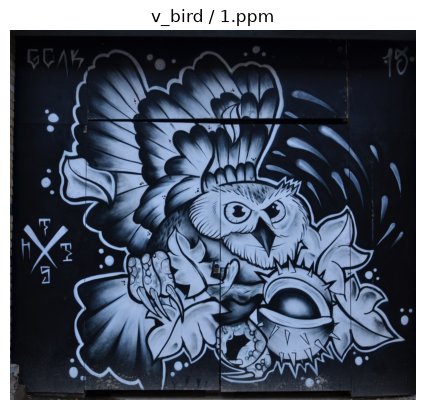

In [25]:
import cv2
import matplotlib.pyplot as plt

category = "v_bird"
img_path = f"hpatches-sequences-release/{category}/1.ppm"

image = cv2.imread(img_path, cv2.IMREAD_COLOR)  # BGR, 3-channel
if image is None:
    raise FileNotFoundError(f"Could not read {img_path}")

print("Shape:", image.shape)  # (h, w, 3)



img_path = "hpatches-sequences-release/v_bird/1.ppm"
image = cv2.imread(img_path, cv2.IMREAD_COLOR)

# OpenCV loads BGR; matplotlib expects RGB
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("v_bird / 1.ppm")
plt.show()



Threshold: 10
Neighborhood type: 2
--------------------------------------------------
Original         | WITH NMS:  7684  | WITHOUT NMS: 38565
Rotated 45°      | WITH NMS:  6267  | WITHOUT NMS: 35636
Translated       | WITH NMS:  7012  | WITHOUT NMS: 35760
Scaled 1.5x      | WITH NMS:  4040  | WITHOUT NMS: 29122
Scaled 0.5x      | WITH NMS:  4662  | WITHOUT NMS: 21758
Combined warp    | WITH NMS:  6706  | WITHOUT NMS: 33170


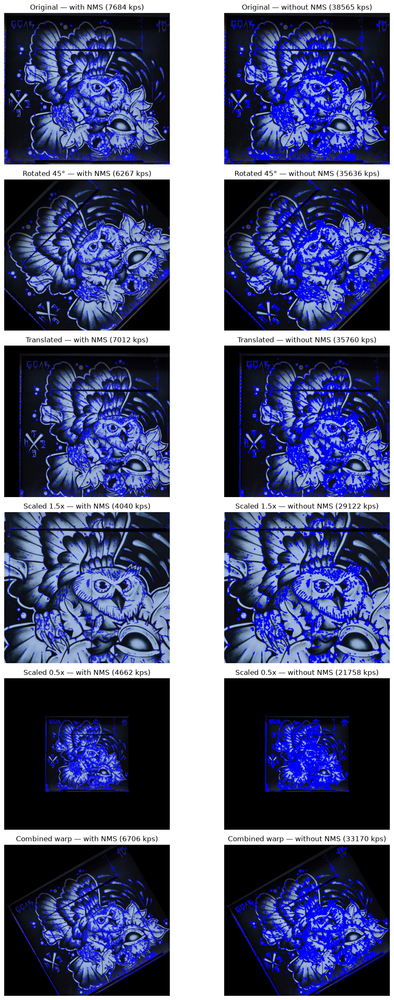

In [26]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

h, w = image.shape[:2]
center = (w / 2, h / 2)

# ---------------------------
# 1. Rotation (e.g., 45 degrees)
# ---------------------------
angle = 45
scale_rot = 1.0
M_rot = cv2.getRotationMatrix2D(center, angle, scale_rot)
img_rotated = cv2.warpAffine(image, M_rot, (w, h))

# ---------------------------
# 2. Translation (shift by tx, ty)
# ---------------------------
tx, ty = 100, 50
M_trans = np.float32([[1, 0, tx],
                      [0, 1, ty]])
img_translated = cv2.warpAffine(image, M_trans, (w, h))

# ---------------------------
# 3. Scale (resize by factor, then crop/pad back to original size)
# ---------------------------
scale_factor = 1.5
img_scaled_full = cv2.resize(image, None, fx=scale_factor, fy=scale_factor,
                             interpolation=cv2.INTER_LINEAR)
# Crop back to original size (center crop)
sh, sw = img_scaled_full.shape[:2]
x0 = (sw - w) // 2
y0 = (sh - h) // 2
img_scaled = img_scaled_full[y0:y0 + h, x0:x0 + w]

scale_factor = 0.5
img_scaled_full2 = cv2.resize(image, None, fx=scale_factor, fy=scale_factor,
                             interpolation=cv2.INTER_LINEAR)
# Pad back to original size (centered, black border)
sh2, sw2 = img_scaled_full2.shape[:2]
pad_x = (w - sw2) // 2
pad_y = (h - sh2) // 2
img_scaled2 = np.zeros_like(image)
img_scaled2[pad_y:pad_y + sh2, pad_x:pad_x + sw2] = img_scaled_full2

# ---------------------------
# 4. Combined warp (rotation + translation + scale in one affine matrix)
# ---------------------------
angle_c = 30
scale_c = 0.8
M_rot_c = cv2.getRotationMatrix2D(center, angle_c, scale_c)
M_rot_c[0, 2] += 50   # add translation x
M_rot_c[1, 2] += 30   # add translation y
img_combined = cv2.warpAffine(image, M_rot_c, (w, h))

# ---------------------------
# Run FAST on each version
# ---------------------------
fast = cv2.FastFeatureDetector_create()

def run_fast(img, use_nms=True):
    fast.setNonmaxSuppression(1 if use_nms else 0)
    kps = fast.detect(img, None)
    out = cv2.drawKeypoints(img, kps, None, color=(255, 0, 0))
    return out, len(kps)

images = {
    "Original":       image,
    "Rotated 45°":    img_rotated,
    "Translated":     img_translated,
    "Scaled 1.5x":    img_scaled,
    "Scaled 0.5x":    img_scaled2,
    "Combined warp":  img_combined,
}

results = {}
for name, im in images.items():
    out_nms, n_nms = run_fast(im, use_nms=True)
    out_no,  n_no  = run_fast(im, use_nms=False)
    results[name] = (out_nms, n_nms, out_no, n_no)

# Print stats
print("Threshold:", fast.getThreshold())
print("Neighborhood type:", fast.getType())
print("-" * 50)
for name, (_, n_nms, _, n_no) in results.items():
    print(f"{name:<16} | WITH NMS: {n_nms:5d}  | WITHOUT NMS: {n_no:5d}")

# ---------------------------
# Display results (rows = transforms, cols = with/without NMS)
# ---------------------------
fig, axes = plt.subplots(len(results), 2, figsize=(12, 4 * len(results)))

for i, (name, (out_nms, n_nms, out_no, n_no)) in enumerate(results.items()):
    axes[i, 0].imshow(cv2.cvtColor(out_nms, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{name} — with NMS ({n_nms} kps)")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(cv2.cvtColor(out_no, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"{name} — without NMS ({n_no} kps)")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

Image                   SIFT        FAST         ORB        KAZE
----------------------------------------------------------------
Original                3361        7684        3000        6111
Rotated 45°             2920        6267        3000        5565
Translated              3058        7012        3000        5720
Scaled 1.5x             2152        4040        3000        5093
Scaled 0.5x             1850        4662        3000        2335
Combined warp           2776        6706        3000        4537


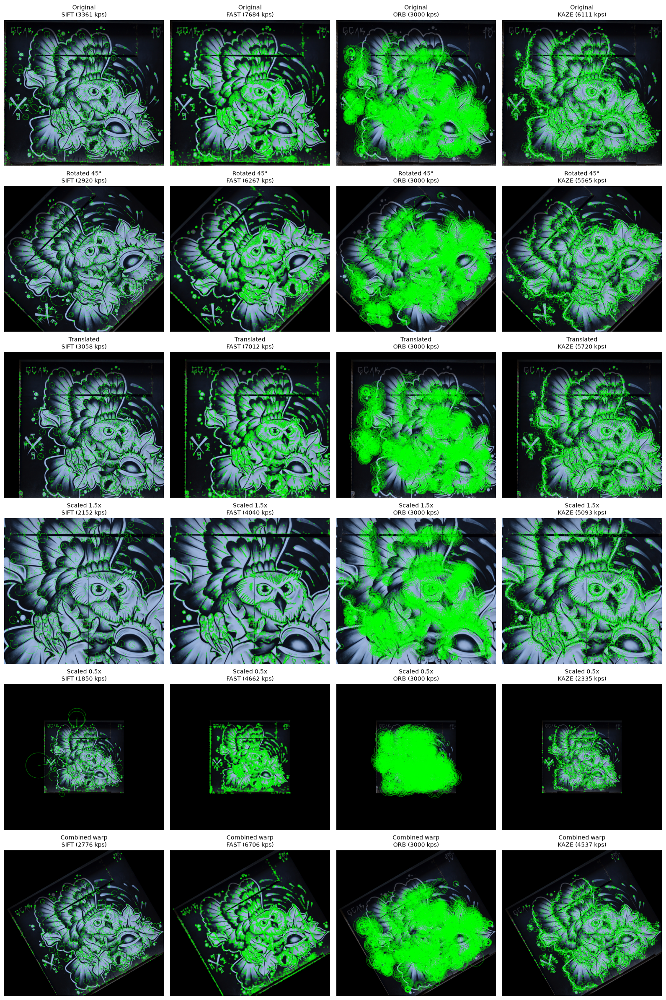

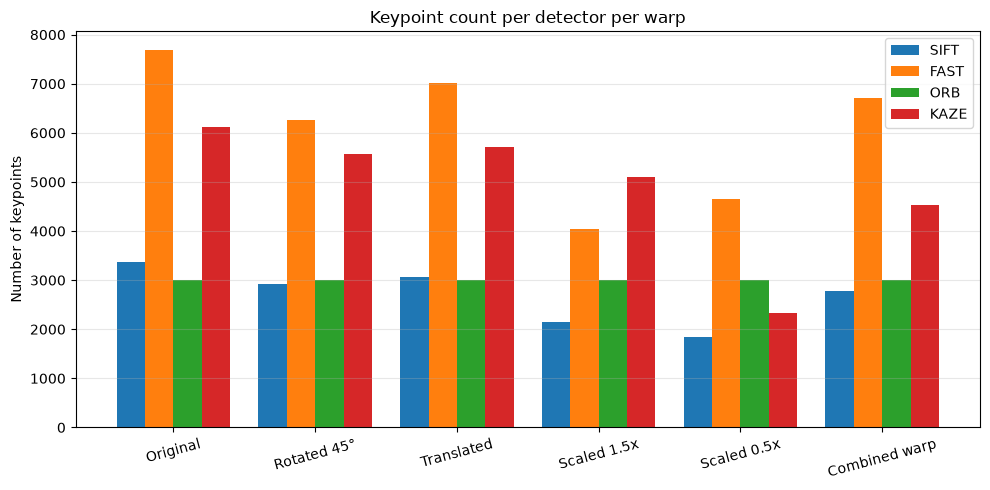

In [27]:
# ---------------------------------------------------------------
# Detector factory: returns (name, detector, draw_func)
# ---------------------------------------------------------------
def make_detectors():
    detectors = []

    # SIFT
    sift = cv2.SIFT_create()
    detectors.append(("SIFT", sift))

    # FAST (no descriptor)
    fast = cv2.FastFeatureDetector_create()
    detectors.append(("FAST", fast))

    # ORB
    orb = cv2.ORB_create(nfeatures=3000)
    detectors.append(("ORB", orb))

    # KAZE
    kaze = cv2.KAZE_create()
    detectors.append(("KAZE", kaze))

    return detectors

# ---------------------------------------------------------------
# Run each detector on each warped image
# ---------------------------------------------------------------
detectors = make_detectors()
results = {}   # results[img_name][det_name] = (annotated_img, n_kps)

for img_name, img in images.items():
    results[img_name] = {}
    # Convert to grayscale for detectors that expect it
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    for det_name, det in detectors:
        try:
            kps = det.detect(gray, None)
        except cv2.error:
            kps = []

        # Draw keypoints (rich drawing to see scale/orientation where available)
        out = cv2.drawKeypoints(
            img, kps, None,
            color=(0, 255, 0),
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
        )
        results[img_name][det_name] = (out, len(kps))

# ---------------------------------------------------------------
# Print a summary table
# ---------------------------------------------------------------
det_names = [d[0] for d in detectors]
header = f"{'Image':<16}" + "".join(f"{d:>12}" for d in det_names)
print(header)
print("-" * len(header))
for img_name in images:
    row = f"{img_name:<16}"
    for d in det_names:
        row += f"{results[img_name][d][1]:>12d}"
    print(row)

# ---------------------------------------------------------------
# Visualize: rows = images, cols = detectors
# ---------------------------------------------------------------
fig, axes = plt.subplots(len(images), len(det_names),
                         figsize=(4 * len(det_names), 4 * len(images)))

for i, img_name in enumerate(images):
    for j, det_name in enumerate(det_names):
        ax = axes[i, j]
        out, n = results[img_name][det_name]
        ax.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{img_name}\n{det_name} ({n} kps)", fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# Optional: bar chart of keypoint counts
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(images))
width = 0.2

for k, det_name in enumerate(det_names):
    counts = [results[img_name][det_name][1] for img_name in images]
    ax.bar(x + k * width, counts, width, label=det_name)

ax.set_xticks(x + width * (len(det_names) - 1) / 2)
ax.set_xticklabels(list(images.keys()), rotation=15)
ax.set_ylabel("Number of keypoints")
ax.set_title("Keypoint count per detector per warp")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Detector         Rotated 45°      Translated     Scaled 1.5x     Scaled 0.5x   Combined warp
--------------------------------------------------------------------------------------------
SIFT                    2072            2938            1356            1425            2045
ORB                     3262            3641            1719            1379            2556
KAZE                    4378            5302            2638            1167            2760
FAST+BRIEF               144            6463             370              87             117
FAST+BRISK              4768            6169              58               3             501
FAST+FREAK              3600            5354              70              12             872


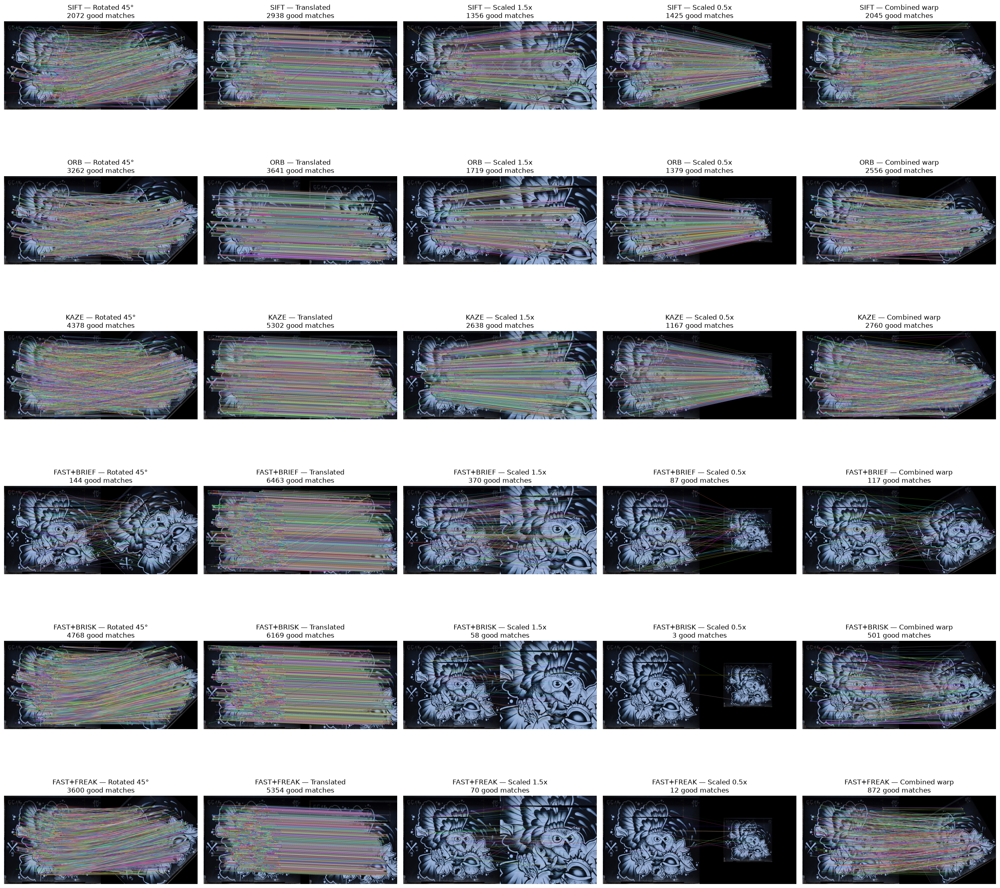

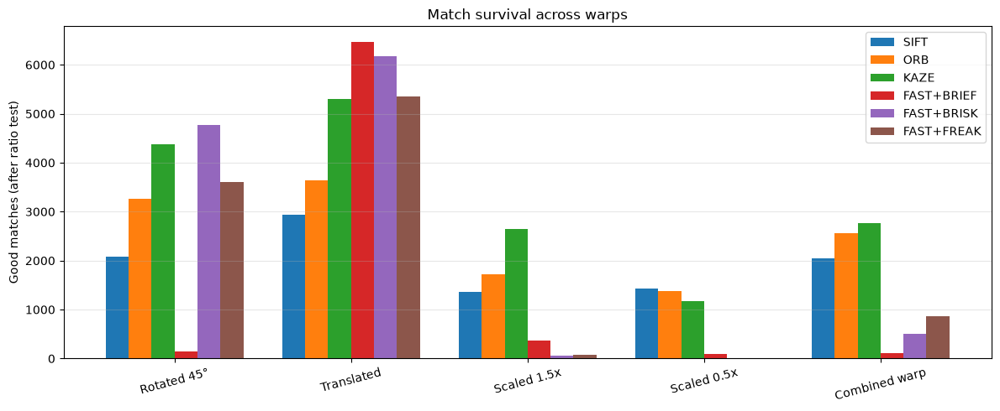

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# assumes `images` dict exists from the first script:
# images = {"Original": image, "Rotated 45°": ..., ...}

original_name = "Original"
img_ref = images[original_name]
gray_ref = cv2.cvtColor(img_ref, cv2.COLOR_BGR2GRAY)


# ---------------------------------------------------------------
# Detector/descriptor factories
#   - classic (detector + descriptor in one):  (obj, norm)
#   - FAST + binary descriptor:                (None, norm, desc_obj)
# ---------------------------------------------------------------
def build_detectors():
    return {
        "SIFT":      (cv2.SIFT_create(),                 cv2.NORM_L2,      None),
        "ORB":       (cv2.ORB_create(nfeatures=5000),    cv2.NORM_HAMMING, None),
        "KAZE":      (cv2.KAZE_create(),                 cv2.NORM_L2,      None),
        "FAST+BRIEF": (None, cv2.NORM_HAMMING,
                       cv2.xfeatures2d.BriefDescriptorExtractor_create()),
        "FAST+BRISK": (None, cv2.NORM_HAMMING,
                       cv2.BRISK_create()),
        "FAST+FREAK": (None, cv2.NORM_HAMMING,
                       cv2.xfeatures2d.FREAK_create()),
    }


def detect_and_describe(det, desc_obj, gray):
    """If desc_obj is None -> use det.detectAndCompute (SIFT/ORB/KAZE).
       Otherwise -> FAST detects, desc_obj computes."""
    if desc_obj is None:
        return det.detectAndCompute(gray, None)

    fast = cv2.FastFeatureDetector_create()
    fast.setNonmaxSuppression(True)
    kp = fast.detect(gray, None)
    if not kp:
        return [], None

    # consistent size/octave so BRISK/FREAK are happy; angle=-1 -> no orientation
    for k in kp:
        k.size = 31.0
        k.octave = 0
        k.angle = -1

    return desc_obj.compute(gray, kp)


# ---------------------------------------------------------------
# Reference keypoints/descriptors (original image)
# ---------------------------------------------------------------
ref_data = {}
for name, (det, norm, desc_obj) in build_detectors().items():
    kp, des = detect_and_describe(det, desc_obj, gray_ref)
    ref_data[name] = (kp, des)


# ---------------------------------------------------------------
# Match each warp against the reference
# ---------------------------------------------------------------
RATIO = 0.75
results = {}  # results[det][warp] = (n_good, n_raw, kp1, kp2, good_matches)

for det_name, (det, norm, desc_obj) in build_detectors().items():
    bf = cv2.BFMatcher(norm, crossCheck=False)
    kp_ref, des_ref = ref_data[det_name]
    results[det_name] = {}

    for warp_name, img_w in images.items():
        if warp_name == original_name:
            continue

        gray_w = cv2.cvtColor(img_w, cv2.COLOR_BGR2GRAY)
        kp_w, des_w = detect_and_describe(det, desc_obj, gray_w)

        if des_ref is None or des_w is None or len(kp_w) < 2 or len(kp_ref) < 2:
            results[det_name][warp_name] = (0, 0, kp_ref, kp_w, [])
            continue

        raw = bf.knnMatch(des_ref, des_w, k=2)

        good = []
        for pair in raw:
            if len(pair) == 2:
                m, n = pair
                if m.distance < RATIO * n.distance:
                    good.append(m)

        results[det_name][warp_name] = (len(good), len(raw), kp_ref, kp_w, good)


# ---------------------------------------------------------------
# Summary table
# ---------------------------------------------------------------
warps = [w for w in images if w != original_name]
header = f"{'Detector':<12}" + "".join(f"{w:>16}" for w in warps)
print(header)
print("-" * len(header))
for det_name, per_warp in results.items():
    row = f"{det_name:<12}"
    for w in warps:
        n_good, _, _, _, _ = per_warp[w]
        row += f"{n_good:>16d}"
    print(row)


# ---------------------------------------------------------------
# Visualize good matches: rows = detector, cols = warp
# ---------------------------------------------------------------
fig, axes = plt.subplots(len(results), len(warps),
                         figsize=(5 * len(warps), 4 * len(results)))
if len(results) == 1:
    axes = [axes]

for i, (det_name, per_warp) in enumerate(results.items()):
    for j, warp_name in enumerate(warps):
        n_good, _, kp_ref, kp_w, good = per_warp[warp_name]
        vis = cv2.drawMatches(
            img_ref, kp_ref,
            images[warp_name], kp_w,
            good, None,
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )
        ax = axes[i][j]
        ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{det_name} — {warp_name}\n{n_good} good matches")
        ax.axis("off")

plt.tight_layout()
plt.show()


# ---------------------------------------------------------------
# Bar chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(warps))
width = 0.13
for k, det_name in enumerate(results):
    counts = [results[det_name][w][0] for w in warps]
    ax.bar(x + k * width, counts, width, label=det_name)

ax.set_xticks(x + width * (len(results) - 1) / 2)
ax.set_xticklabels(warps, rotation=15)
ax.set_ylabel("Good matches (after ratio test)")
ax.set_title("Match survival across warps")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:

# -------------------------------------------------------------------
# 1. Build the exact 3x3 homography that maps ORIGINAL -> each warp
#    (must match exactly how the warps were produced in script 1)
# -------------------------------------------------------------------
def to_h3(M2x3):
    """Promote a 2x3 affine matrix to a 3x3 homography."""
    H = np.eye(3, dtype=np.float64)
    H[:2, :] = M2x3
    return H

h, w = image.shape[:2]
center = (w / 2, h / 2)

# Rotation 45°
angle = 45; scale_rot = 1.0
M_rot = cv2.getRotationMatrix2D(center, angle, scale_rot)
H_rot = to_h3(M_rot)

# Translation (100, 50)
M_trans = np.float32([[1, 0, 100],
                      [0, 1,  50]])
H_trans = to_h3(M_trans)

# Scale 1.5x, then center-crop back to (w, h)
scale_factor = 1.5
# resize: x' = s*x ; then crop offset (x0, y0)
sh = int(round(h * scale_factor)); sw = int(round(w * scale_factor))
x0 = (sw - w) // 2; y0 = (sh - h) // 2
H_scale15 = np.array([[scale_factor, 0,            -x0],
                      [0,            scale_factor, -y0],
                      [0,            0,             1]], dtype=np.float64)

# Scale 0.5x, then center-pad back to (w, h)
scale_factor = 0.5
sh2 = int(round(h * scale_factor)); sw2 = int(round(w * scale_factor))
pad_x = (w - sw2) // 2; pad_y = (h - sh2) // 2
H_scale05 = np.array([[scale_factor, 0,            pad_x],
                      [0,            scale_factor, pad_y],
                      [0,            0,             1]], dtype=np.float64)

# Combined warp (rotation 30° + scale 0.8 + translation 50,30)
angle_c = 30; scale_c = 0.8
M_rot_c = cv2.getRotationMatrix2D(center, angle_c, scale_c)
M_rot_c[0, 2] += 50
M_rot_c[1, 2] += 30
H_combined = to_h3(M_rot_c)

GT_HOMOGRAPHIES = {
    "Original":      np.eye(3),
    "Rotated 45°":   H_rot,
    "Translated":    H_trans,
    "Scaled 1.5x":   H_scale15,
    "Scaled 0.5x":   H_scale05,
    "Combined warp": H_combined,
}

In [30]:
# -------------------------------------------------------------------
# 2. Compute the four metrics for one (ref, warp) pair
# -------------------------------------------------------------------
def project_points(H, pts_xy):
    """Apply a 3x3 homography to an (N,2) array of (x, y) points."""
    pts = np.asarray(pts_xy, dtype=np.float64).reshape(-1, 1, 2)
    out = cv2.perspectiveTransform(pts, H).reshape(-1, 2)
    return out


def evaluate_pair(kp_ref, kp_warp, H, img_warp_shape,
                  matches, correct_thresh=3.0):
    """
    kp_ref, kp_warp : lists of cv2.KeyPoint
    H               : 3x3 homography mapping ORIGINAL -> warp (pixel coords)
    img_warp_shape  : (h, w) of the warped image, to test 'inside image'
    matches         : list of cv2.DMatch (queryIdx into kp_ref, trainIdx into kp_warp)
                      MUST be one-to-one
    correct_thresh  : correctness radius in pixels (3.0 per assignment)
    """
    n_ref = len(kp_ref)

    # --- reference keypoints projected into the warped image frame ---
    ref_xy   = np.array([k.pt for k in kp_ref],   dtype=np.float64)
    warp_xy  = np.array([k.pt for k in kp_warp],  dtype=np.float64)

    if n_ref == 0 or len(kp_warp) == 0:
        return dict(n_features=n_ref, n_putative=0, n_correct=0,
                    n_correspondences=0,
                    PMR=0.0, Precision=0.0, MatchingScore=0.0, Recall=0.0)

    proj_ref = project_points(H, ref_xy)  # (n_ref, 2)

    # --- ground-truth correspondences ---
    # Reference keypoints whose projection falls inside the warped image.
    Hw, Ww = img_warp_shape
    inside = ((proj_ref[:, 0] >= 0) & (proj_ref[:, 0] < Ww) &
              (proj_ref[:, 1] >= 0) & (proj_ref[:, 1] < Hh)) if False else \
             ((proj_ref[:, 0] >= 0) & (proj_ref[:, 0] < Ww) &
              (proj_ref[:, 1] >= 0) & (proj_ref[:, 1] < Hw))
    n_correspondences = int(inside.sum())

    # --- putative matches (one-to-one assumed) ---
    n_putative = len(matches)

    # --- correct matches ---
    n_correct = 0
    for m in matches:
        p_ref_proj = proj_ref[m.queryIdx]
        p_warp     = warp_xy[m.trainIdx]
        if np.linalg.norm(p_ref_proj - p_warp) <= correct_thresh:
            n_correct += 1

    # --- metrics ---
    PMR            = n_putative / n_ref if n_ref > 0 else 0.0
    Precision      = n_correct / n_putative if n_putative > 0 else 0.0
    MatchingScore  = n_correct / n_ref if n_ref > 0 else 0.0
    Recall         = n_correct / n_correspondences if n_correspondences > 0 else 0.0

    return dict(
        n_features        = n_ref,
        n_putative        = n_putative,
        n_correct         = n_correct,
        n_correspondences = n_correspondences,
        PMR=PMR, Precision=Precision,
        MatchingScore=MatchingScore, Recall=Recall,
    )

In [31]:
# -------------------------------------------------------------------
# 3. Enforce one-to-one matching
#    (ratio test alone does not guarantee uniqueness)
# -------------------------------------------------------------------
def unique_matches(matches, query_key='queryIdx', train_key='trainIdx'):
    """
    Keep, for each query index, the single best (lowest distance) match.
    Also enforce that each train index is used at most once.
    Greedy: sort by distance ascending, then accept first-come-first-served.
    """
    matches = sorted(matches, key=lambda m: m.distance)
    seen_q, seen_t, kept = set(), set(), []
    for m in matches:
        q = getattr(m, query_key)
        t = getattr(m, train_key)
        if q in seen_q or t in seen_t:
            continue
        seen_q.add(q); seen_t.add(t)
        kept.append(m)
    return kept

In [32]:
import pandas as pd
# -------------------------------------------------------------------
# 4. Run evaluation for all detectors x warps
#    Uses the `results` dict you already built in the previous script:
#    results[det][warp] = (n_good, n_raw, kp_ref, kp_w, good_matches)
# -------------------------------------------------------------------
RATIO      = 0.8    # assignment reference protocol
CORRECT_T  = 3.0    # assignment reference protocol (pixels)

rows = []
for det_name, per_warp in results.items():
    for warp_name, (_, _, kp_ref, kp_w, good) in per_warp.items():

        H = GT_HOMOGRAPHIES[warp_name]
        img_warp_shape = images[warp_name].shape[:2]

        # one-to-one enforcement
        good_u = unique_matches(good)

        metrics = evaluate_pair(
            kp_ref, kp_w, H, img_warp_shape,
            good_u, correct_thresh=CORRECT_T
        )

        rows.append({
            "Detector": det_name,
            "Warp":     warp_name,
            **metrics
        })

df_metrics = pd.DataFrame(rows)

# Pretty print, ordered
cols = ["Detector", "Warp",
        "n_features", "n_putative", "n_correct", "n_correspondences",
        "PMR", "Precision", "MatchingScore", "Recall"]
df_metrics = df_metrics[cols].sort_values(["Detector", "Warp"])
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 200)
print(df_metrics.to_string(index=False))

  Detector          Warp  n_features  n_putative  n_correct  n_correspondences    PMR  Precision  MatchingScore  Recall
FAST+BRIEF Combined warp        7363          98          2               7337 0.0133     0.0204         0.0003  0.0003
FAST+BRIEF   Rotated 45°        7363         117          0               6988 0.0159     0.0000         0.0000  0.0000
FAST+BRIEF   Scaled 0.5x        7363          77          6               7363 0.0105     0.0779         0.0008  0.0008
FAST+BRIEF   Scaled 1.5x        7363         274        102               4962 0.0372     0.3723         0.0139  0.0206
FAST+BRIEF    Translated        7363        6429       6429               6867 0.8731     1.0000         0.8731  0.9362
FAST+BRISK Combined warp        6968         437        347               6960 0.0627     0.7941         0.0498  0.0499
FAST+BRISK   Rotated 45°        6968        4038       3944               6719 0.5795     0.9767         0.5660  0.5870
FAST+BRISK   Scaled 0.5x        6968    

In [34]:
import os
import json
import cv2

# -------------------------------------------------------------------
# 5. Save metrics to results/ (reproducibility, Assignment §7)
#    Run cells above first: needs df_metrics, ref_data, images,
#    GT_HOMOGRAPHIES, RATIO (0.75 in matching cell), CORRECT_T (3.0)
# -------------------------------------------------------------------
out_dir = "results"
os.makedirs(out_dir, exist_ok=True)

if "df_metrics" not in globals():
    raise RuntimeError("Run the evaluation cell first: df_metrics not found.")

# 1. Main matching table: PMR / Precision / MatchingScore / Recall
metrics_path = os.path.join(out_dir, "notebook_matching_metrics.csv")
df_metrics.to_csv(metrics_path, index=False)
print(f"Wrote {metrics_path} ({len(df_metrics)} rows)")

# 2. Descriptor dimensionality + memory (from reference image)
desc_rows = []
for det_name, (kp, des) in ref_data.items():
    if des is None:
        desc_rows.append({"Detector": det_name, "n_features": len(kp), "dim": 0, "dtype": "none", "bytes_per_desc": 0, "total_bytes": 0})
    else:
        desc_rows.append({"Detector": det_name, "n_features": len(kp), "dim": int(des.shape[1]), "dtype": str(des.dtype), "bytes_per_desc": int(des.itemsize * des.shape[1]), "total_bytes": int(des.nbytes)})
desc_info = pd.DataFrame(desc_rows).sort_values("Detector")
desc_path = os.path.join(out_dir, "notebook_descriptor_info.csv")
desc_info.to_csv(desc_path, index=False)
print(desc_info.to_string(index=False))
print(f"Wrote {desc_path}")

# 3. Run config: thresholds, image, homographies, versions
config = {
    "matching_ratio": 0.75,
    "correct_thresh_px": float(CORRECT_T),
    "one_to_one": True,
    "opencv_version": cv2.__version__,
    "image_shape_hw": list(images["Original"].shape[:2]),
    "warps": sorted([w for w in images if w != "Original"]),
    "homographies": {k: v.tolist() for k, v in GT_HOMOGRAPHIES.items()},
}
cfg_path = os.path.join(out_dir, "notebook_run_config.json")
with open(cfg_path, "w") as f:
    json.dump(config, f, indent=2)
print(f"Wrote {cfg_path}")


Wrote results\notebook_matching_metrics.csv (30 rows)
  Detector  n_features  dim   dtype  bytes_per_desc  total_bytes
FAST+BRIEF        7363   32   uint8              32       235616
FAST+BRISK        6968   64   uint8              64       445952
FAST+FREAK        6175   64   uint8              64       395200
      KAZE        6111   64 float32             256      1564416
       ORB        5000   32   uint8              32       160000
      SIFT        3361  128 float32             512      1720832
Wrote results\notebook_descriptor_info.csv
Wrote results\notebook_run_config.json


Threshold: 10
Neighborhood type: 2
Keypoints WITH NMS   : 7684
Keypoints WITHOUT NMS: 38565


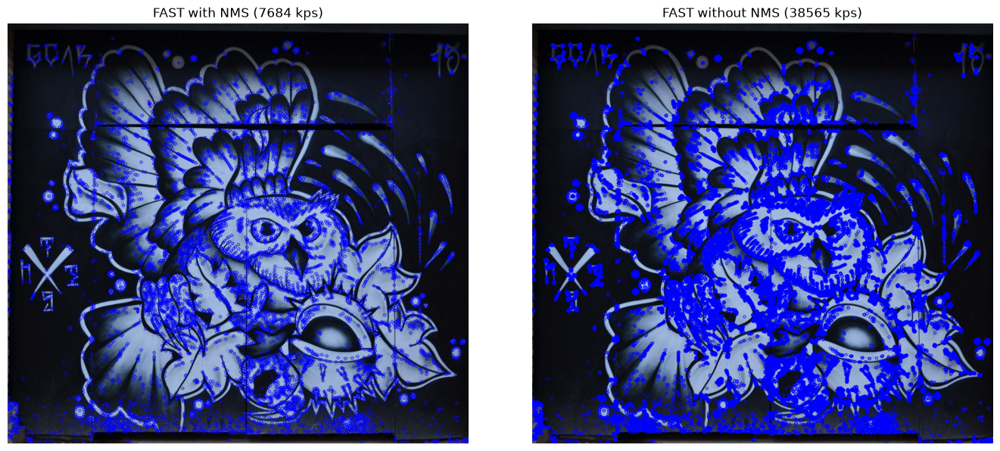

In [ ]:
# import cv2
# import matplotlib.pyplot as plt

# fast = cv2.FastFeatureDetector_create()

# # --- With non-max suppression ---
# kp_true = fast.detect(image, None)
# img_true = cv2.drawKeypoints(image, kp_true, None, color=(255, 0, 0))

# # --- Without non-max suppression ---
# fast.setNonmaxSuppression(0)
# kp_false = fast.detect(image, None)
# img_false = cv2.drawKeypoints(image, kp_false, None, color=(255, 0, 0))

# # Print stats
# print("Threshold:", fast.getThreshold())
# print("Neighborhood type:", fast.getType())
# print(f"Keypoints WITH NMS   : {len(kp_true)}")
# print(f"Keypoints WITHOUT NMS: {len(kp_false)}")

# # Convert BGR -> RGB for matplotlib
# fig, ax = plt.subplots(1, 2, figsize=(14, 6))
# ax[0].imshow(cv2.cvtColor(img_true,  cv2.COLOR_BGR2RGB))
# ax[0].set_title(f"FAST with NMS ({len(kp_true)} kps)")
# ax[0].axis("off")

# ax[1].imshow(cv2.cvtColor(img_false, cv2.COLOR_BGR2RGB))
# ax[1].set_title(f"FAST without NMS ({len(kp_false)} kps)")
# ax[1].axis("off")

# plt.tight_layout()
# plt.show()

Image 1: 7363 kps, descriptors (7363, 32)
Image 2: 9952 kps, descriptors (9952, 32)
Total matches: 1598
Best match distance: 12.0


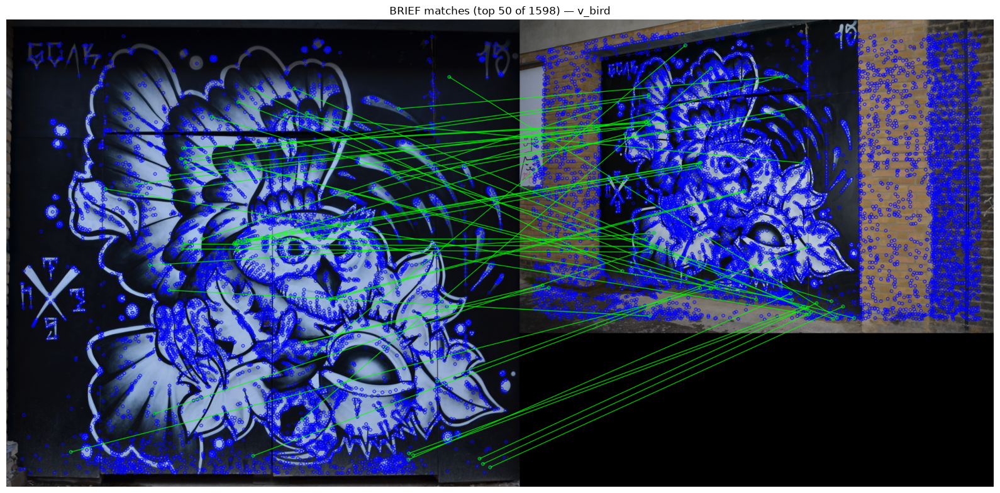

In [ ]:
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# # ---- Load pair ----
# category = "v_bird"
# img1 = cv2.imread(f"hpatches-sequences-release/{category}/1.ppm", cv2.IMREAD_COLOR)
# img2 = cv2.imread(f"hpatches-sequences-release/{category}/2.ppm", cv2.IMREAD_COLOR)
# gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
# gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# # ---- Detectors / descriptors ----
# fast  = cv2.FastFeatureDetector_create()
# brief = cv2.xfeatures2d.BriefDescriptorExtractor_create(bytes=32, use_orientation=False)

# # Image 1
# kp1 = fast.detect(gray1, None)
# kp1, des1 = brief.compute(gray1, kp1)

# # Image 2
# kp2 = fast.detect(gray2, None)
# kp2, des2 = brief.compute(gray2, kp2)

# print(f"Image 1: {len(kp1)} kps, descriptors {des1.shape}")
# print(f"Image 2: {len(kp2)} kps, descriptors {des2.shape}")

# # ---- Match with Hamming distance (BRIEF is binary) ----
# bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
# matches = bf.match(des1, des2)
# matches = sorted(matches, key=lambda m: m.distance)

# print(f"Total matches: {len(matches)}")
# print(f"Best match distance: {matches[0].distance}")

# # ---- Draw top 50 matches ----
# draw_params = dict(matchColor=(0, 255, 0),
#                    singlePointColor=(255, 0, 0),
#                    flags=cv2.DrawMatchesFlags_DEFAULT)

# matched_img = cv2.drawMatches(img1, kp1, img2, kp2, matches[:50], None, **draw_params)

# # ---- Show ----
# plt.figure(figsize=(16, 8))
# plt.imshow(cv2.cvtColor(matched_img, cv2.COLOR_BGR2RGB))
# plt.title(f"BRIEF matches (top 50 of {len(matches)}) — {category}")
# plt.axis("off")
# plt.tight_layout()
# plt.show()

In [ ]:
# import numpy as np
# import cv2

# def project(H, pts):
#     """Project Nx2 points through 3x3 homography H."""
#     pts_h = np.hstack([pts, np.ones((len(pts), 1))])   # (N,3)
#     proj  = (H @ pts_h.T).T                            # (N,3)
#     return proj[:, :2] / proj[:, 2:3]                  # (N,2)

# def evaluate_matches(kp1, kp2, matches, H, threshold=3.0):
#     """
#     Returns dict with:
#       - correct: number of matches whose reprojection error < threshold
#       - total:   number of matches evaluated
#       - precision: correct / total
#       - errors:  per-match reprojection errors
#     """
#     pts1 = np.float32([kp1[m.queryIdx].pt for m in matches])
#     pts2 = np.float32([kp2[m.trainIdx].pt for m in matches])
#     pts1_proj = project(H, pts1)
#     errors = np.linalg.norm(pts1_proj - pts2, axis=1)
#     correct = int((errors < threshold).sum())
#     return {
#         "correct": correct,
#         "total": len(matches),
#         "precision": correct / max(len(matches), 1),
#         "errors": errors,
#     }

In [ ]:
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# # ---------- Load ----------
# category = "v_bird"
# img1 = cv2.imread(f"hpatches-sequences-release/{category}/1.ppm", cv2.IMREAD_COLOR)
# img2 = cv2.imread(f"hpatches-sequences-release/{category}/2.ppm", cv2.IMREAD_COLOR)
# H_gt = np.loadtxt(f"hpatches-sequences-release/{category}/H_1_2")

# g1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
# g2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# # ---------- Detect + describe ----------
# fast  = cv2.FastFeatureDetector_create()
# brief = cv2.xfeatures2d.BriefDescriptorExtractor_create(bytes=32, use_orientation=False)

# kp1 = fast.detect(g1, None)
# kp1, des1 = brief.compute(g1, kp1)

# kp2 = fast.detect(g2, None)
# kp2, des2 = brief.compute(g2, kp2)

# # ---------- Match with ratio test ----------
# bf = cv2.BFMatcher(cv2.NORM_HAMMING)
# knn = bf.knnMatch(des1, des2, k=2)

# good = [m for m, n in knn if m.distance < 0.75 * n.distance]
# print(f"Ratio-test matches: {len(good)}")

# # ---------- Evaluate against GT H ----------
# result = evaluate_matches(kp1, kp2, good, H_gt, threshold=3.0)
# print(f"Correct matches @3px: {result['correct']} / {result['total']}")
# print(f"Precision: {result['precision']:.3f}")

# # ---------- Match with cross-check ----------
# bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
# good = bf.match(des1, des2)

# # Optional: sort by distance (bf.match doesn't guarantee order)
# good = sorted(good, key=lambda m: m.distance)
# print(f"Cross-check matches: {len(good)}")

# # ---------- Evaluate against GT H ----------
# result = evaluate_matches(kp1, kp2, good, H_gt, threshold=3.0)
# print(f"Correct matches @3px: {result['correct']} / {result['total']}")
# print(f"Precision: {result['precision']:.3f}")

Ratio-test matches: 78
Correct matches @3px: 6 / 78
Precision: 0.077
Cross-check matches: 1598
Correct matches @3px: 99 / 1598
Precision: 0.062


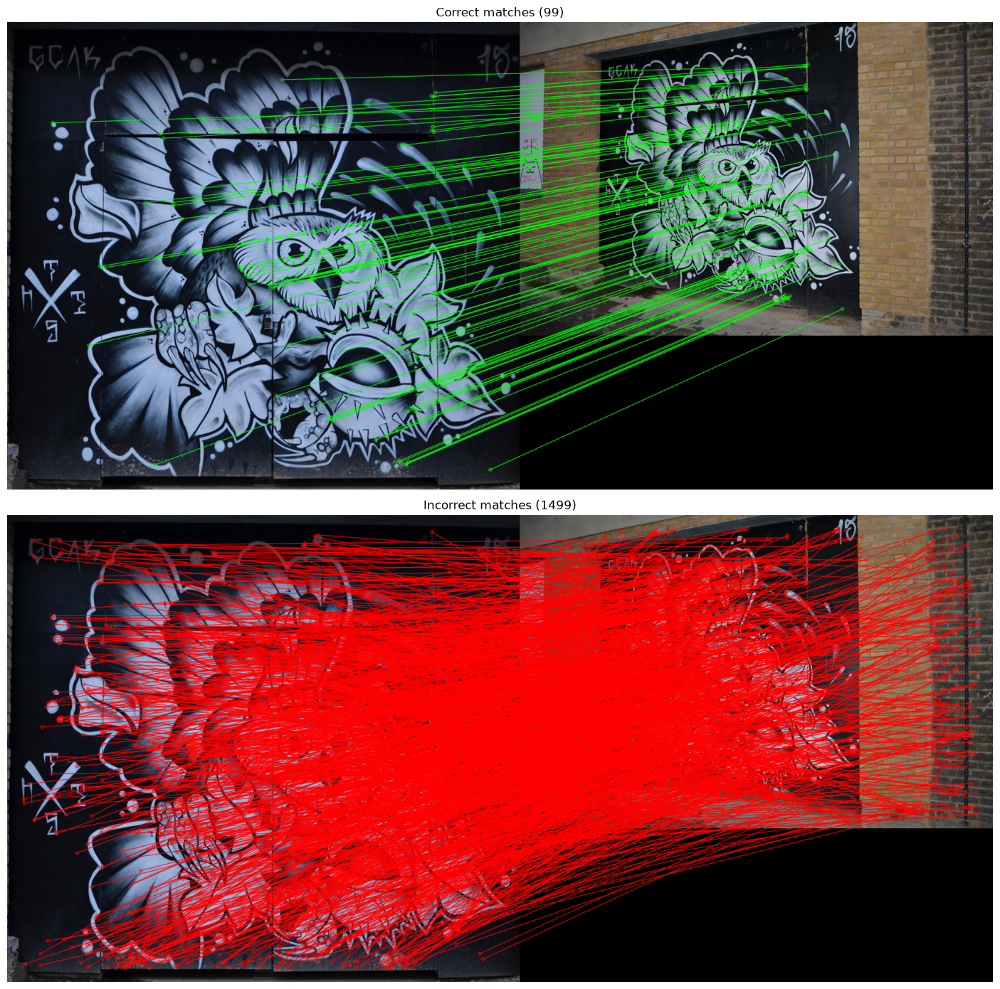

In [ ]:
# pts1 = np.float32([kp1[m.queryIdx].pt for m in good])
# pts2 = np.float32([kp2[m.trainIdx].pt for m in good])
# pts1_proj = project(H_gt, pts1)
# errors = np.linalg.norm(pts1_proj - pts2, axis=1)
# correct_mask = errors < 3.0

# # Split into correct / incorrect match lists
# correct   = [m for m, c in zip(good, correct_mask) if c]
# incorrect = [m for m, c in zip(good, correct_mask) if not c]

# out_correct   = cv2.drawMatches(img1, kp1, img2, kp2, correct,   None,
#                                 matchColor=(0, 255, 0), flags=2)   # green
# out_incorrect = cv2.drawMatches(img1, kp1, img2, kp2, incorrect, None,
#                                 matchColor=(0, 0, 255), flags=2)   # red

# fig, ax = plt.subplots(2, 1, figsize=(16, 14))
# ax[0].imshow(cv2.cvtColor(out_correct, cv2.COLOR_BGR2RGB))
# ax[0].set_title(f"Correct matches ({len(correct)})")
# ax[0].axis("off")
# ax[1].imshow(cv2.cvtColor(out_incorrect, cv2.COLOR_BGR2RGB))
# ax[1].set_title(f"Incorrect matches ({len(incorrect)})")
# ax[1].axis("off")
# plt.tight_layout()
# plt.show()

## Read Image and Homography


module://matplotlib_inline.backend_inline
Image 1 shape: (973, 1068, 3)
Image 2 shape: (653, 986, 3)
Points shape: (5, 2)


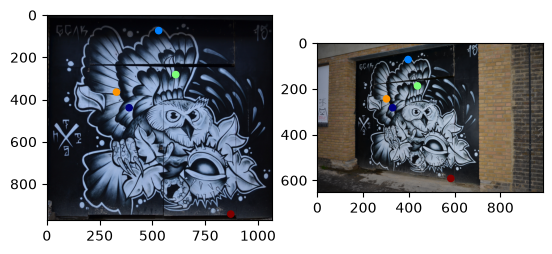

In [ ]:
# import cv2, numpy as np, random
# import matplotlib.pyplot as plt
# from matplotlib import cm
# import matplotlib

# print(matplotlib.get_backend())

# category = "v_bird"
# image1_path = f"hpatches-sequences-release/{category}/1.ppm"
# image2_path = f"hpatches-sequences-release/{category}/2.ppm"
# H12_path = f"hpatches-sequences-release/{category}/H_1_2"

# # read images and homography matrix
# image1 = cv2.imread(image1_path, 1) # 0: grayscale | 1: bgr
# image2 = cv2.imread(image2_path, 1) # 0: grayscale | 1: bgr
# H = np.loadtxt(H12_path)

# # Check image shape
# print("Image 1 shape:", image1.shape)
# print("Image 2 shape:", image2.shape)

# h1, w1 = image1.shape[:2]
# h2, w2 = image2.shape[:2]

# # generate random points
# num_points = 5
# np.random.seed(58) #reproducibility
# pts = np.random.rand(num_points, 2,) * np.array([w1,h1])
# print("Points shape:", pts.shape)

# # Project transformation
# pts = np.hstack([pts, np.ones((num_points,1))]) # [x,y,1]
# pts_t = (H @ pts.T).T
# pts_t = pts_t[:, :2] / pts_t[:, 2:3]

# # Plot Figures
# fig, ax = plt.subplots(1,2)
# colors = cm.jet(np.linspace(0,1, len(pts)))
# ax[0].imshow(cv2.cvtColor(image1, cv2.COLOR_BGR2RGB))
# ax[0].scatter(pts[:,0], pts[:,1], s=20, c=colors)
# ax[1].imshow(cv2.cvtColor(image2, cv2.COLOR_BGR2RGB))
# ax[1].scatter(pts_t[:,0], pts_t[:,1], s=20, c=colors)
# plt.show()

In [ ]:
# import cv2
# import numpy as np
# import itertools

# # --- Your evaluation function ---
# def evaluate_pipeline(g1, g2, H_gt, fast_params, brief_params):
#     fast = cv2.FastFeatureDetector_create(**fast_params)
#     brief = cv2.xfeatures2d.BriefDescriptorExtractor_create(**brief_params)

#     kp1 = fast.detect(g1, None)
#     kp1, d1 = brief.compute(g1, kp1)
#     kp2 = fast.detect(g2, None)
#     kp2, d2 = brief.compute(g2, kp2)

#     if d1 is None or d2 is None or len(d1) < 4 or len(d2) < 4:
#         return None

#     # Ratio test
#     bf = cv2.BFMatcher(cv2.NORM_HAMMING)
#     knn = bf.knnMatch(d1, d2, k=2)
#     good = [m for m, n in knn if m.distance < 0.75 * n.distance]

#     if len(good) < 4:
#         return None

#     # Evaluate against GT
#     pts1 = np.float32([kp1[m.queryIdx].pt for m in good])
#     pts2 = np.float32([kp2[m.trainIdx].pt for m in good])
#     pts1_h = np.hstack([pts1, np.ones((len(pts1),1))])
#     proj = (H_gt @ pts1_h.T).T
#     proj = proj[:, :2] / proj[:, 2:3]
#     errors = np.linalg.norm(proj - pts2, axis=1)
#     correct = (errors < 3.0).sum()

#     return {
#         "n_matches": len(good),
#         "correct": correct,
#         "precision": correct / len(good),
#     }

# # --- Parameter grid ---
# fast_grid = [
#     {"threshold": 10, "nonmaxSuppression": True, "type": cv2.FAST_FEATURE_DETECTOR_TYPE_9_16},
#     {"threshold": 20, "nonmaxSuppression": True, "type": cv2.FAST_FEATURE_DETECTOR_TYPE_9_16},
#     {"threshold": 30, "nonmaxSuppression": True, "type": cv2.FAST_FEATURE_DETECTOR_TYPE_9_16},
#     {"threshold": 20, "nonmaxSuppression": True, "type": cv2.FAST_FEATURE_DETECTOR_TYPE_7_12},
#     {"threshold": 20, "nonmaxSuppression": True, "type": cv2.FAST_FEATURE_DETECTOR_TYPE_5_8},
# ]

# brief_grid = [
#     {"bytes": 16, "use_orientation": False},
#     {"bytes": 32, "use_orientation": False},
#     {"bytes": 64, "use_orientation": False},
# ]

# # --- Run grid search on a few sequences ---
# # Load your images and H_gt first (see previous answers)
# # Then loop:
# for fp, bp in itertools.product(fast_grid, brief_grid):
#     result = evaluate_pipeline(g1, g2, H_gt, fp, bp)
#     if result:
#         print(f"FAST={fp['threshold']}/{fp['type']}, BRIEF={bp['bytes']}B: "
#               f"{result['n_matches']} matches, "
#               f"precision={result['precision']:.3f}")

FAST=10/2, BRIEF=16B: 194 matches, precision=0.067
FAST=10/2, BRIEF=32B: 78 matches, precision=0.077
FAST=10/2, BRIEF=64B: 46 matches, precision=0.130
FAST=20/2, BRIEF=16B: 104 matches, precision=0.115
FAST=20/2, BRIEF=32B: 47 matches, precision=0.128
FAST=20/2, BRIEF=64B: 27 matches, precision=0.074
FAST=30/2, BRIEF=16B: 74 matches, precision=0.081
FAST=30/2, BRIEF=32B: 31 matches, precision=0.129
FAST=30/2, BRIEF=64B: 22 matches, precision=0.273
FAST=20/1, BRIEF=16B: 84 matches, precision=0.179
FAST=20/1, BRIEF=32B: 29 matches, precision=0.276
FAST=20/1, BRIEF=64B: 22 matches, precision=0.409


In [ ]:
#TODO valutare separatamente detectors, descriptors ecc

## DEMO SuperPoint + SuperGlue

In [ ]:
# # Import Models
# import torch
# from SuperGluePretrainedNetwork.models.superglue import SuperGlue
# from SuperGluePretrainedNetwork.models.superpoint import SuperPoint

# device= "cuda" if torch.cuda.is_available() else "cpu"
# print('Running inference on device \"{}\"'.format(device))

# superpoint = SuperPoint(dict(
#     nms_radius=4,
#     keypoint_threshold=0.5,
#     max_keypoints=40
#     )).eval().to(device)


# superglue = SuperGlue(dict(
#     weights='outdoor',  # 'indoor' or 'outdoor'
#     sinkhorn_iterations=20,
#     match_threshold=0.2,
#     )).eval().to(device)

Running inference on device "cpu"
Loaded SuperPoint model
Loaded SuperGlue model ("outdoor" weights)


## Detect keypoints and Match

In [ ]:
# # detect keypoints and compute local descriptors
# from SuperGluePretrainedNetwork.models.utils import read_image
# from SuperGluePretrainedNetwork.models.utils import make_matching_plot
# matplotlib.use("Agg")

# superpoint.config['max_keypoints'] = 100

# resize = [640, 480] #

# # read images with resize transformation
# image0, inp0, scales0 = read_image(image1_path, device, resize, 0, resize_float=False)
# image1, inp1, scales1 = read_image(image2_path, device, resize, 0, resize_float=False)

# # prepare data for superpoint model
# data = {'image0': inp0, 'image1': inp1}

# with torch.no_grad():

#     # Extract Keypoints with superpoint for both images
#     pred0 = superpoint({'image': data['image0']})
#     pred1 = superpoint({'image': data['image1']})

#     # Merge representations into a single dictionary structure
#     data = {**data,**{k+'0': v for k, v in pred0.items()}}
#     data = {**data,**{k+'1': v for k, v in pred1.items()}}

#     for k in data:
#         if isinstance(data[k], (list, tuple)):
#             data[k] = torch.stack(data[k])
#         print(f"Key={k} Dtype={type(data[k])} Shape:{data[k].shape}")

#     # Compute Matches with superglue
#     out_match = superglue(data)
#     pred = {**data,  **out_match}
#     pred = {k: v[0].cpu().numpy() for k, v in pred.items()}


# # print(pred.keys())
# kpts0, kpts1 = pred['keypoints0'], pred['keypoints1']
# matches, conf = pred['matches0'], pred['matching_scores0']

# out_matches = {
#     'keypoints0': kpts0,
#     'keypoints1': kpts1,
#     'matches': matches,
#     'match_confidence': conf
# }

# valid = (matches > -1) # valid matches have value greater than -1
# mkpts0 = kpts0[valid]
# mkpts1 = kpts1[matches[valid]]
# mconf = conf[valid]
# print(f"Found {len(mkpts0)} matches")

Key=image0 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 1, 480, 640])
Key=image1 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 1, 480, 640])
Key=keypoints0 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 97, 2])
Key=scores0 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 97])
Key=descriptors0 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 256, 97])
Key=keypoints1 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 100, 2])
Key=scores1 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 100])
Key=descriptors1 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 256, 100])
Found 26 matches


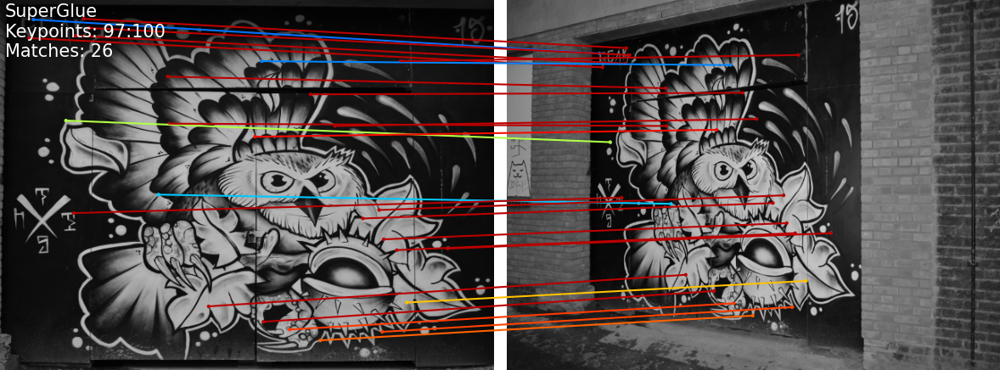

In [ ]:
# from PIL import Image
# text = [
#     'SuperGlue',
#     'Keypoints: K0{}:K1{}'.format(len(kpts0), len(kpts1)),
#     'Matches: {}'.format(len(mkpts0)),
# ]

# make_matching_plot(
#     image0, image1,
#     kpts0, kpts1,
#     mkpts0, mkpts1,
#     color = cm.jet(mconf),
#     text=text,
#     path="test.png",
#     show_keypoints=False,
#     fast_viz=False,
#     opencv_display=False
#     )

# small_text = "\n".join(text)
# display(Image.open("test.png"))

## Saving and loading Matlab files

In [ ]:
# import scipy.io

# A = np.array([[1, 2], [3, 4]])
# print("Array")
# print(A)
# scipy.io.savemat('test.mat', mdict={'A': A})

# # load matlab file
# mat = scipy.io.loadmat('test.mat')
# print(mat['A'])

Array
[[1 2]
 [3 4]]
[[1 2]
 [3 4]]


In [ ]:
# # Save outputs to matlab
# out_matches = {
#     'keypoints0': kpts0,
#     'keypoints1': kpts1,
#     'matches': matches,
#     'match_confidence': conf
# }

# scipy.io.savemat('output.mat', mdict=out_matches)
